In [71]:
from pathlib import Path

retrieval_dir = Path("../src/radar_lwc/retrieval").resolve()
print(retrieval_dir)
print(list(retrieval_dir.glob("*.py")))


C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval
[WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/average_ze_time.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/ddwr_dh.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/dielectric.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/dq_retrieval.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/gas_attenuation.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/kappa_liquid.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/rpg_chirp_table.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/zhu.py')]


In [72]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

sys.path.append(str(Path("../src").resolve()))

# Preprocessing
from radar_lwc.preprocessing.align import align_to_reference_time
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity

# Retrieval
from radar_lwc.retrieval.average_ze_time import avg_ze_time
from radar_lwc.retrieval.dielectric import epsilon_water_liebe1989
from radar_lwc.retrieval.kappa_liquid import kappa_liquid
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu
# NEW: integral DQ retrieval. Copy dq_retrieval.py into src/radar_lwc/retrieval/
from radar_lwc.retrieval.dq_retrieval import retrieve_lwc_dq


In [73]:
Processed_Dataset = "20261001_pallas_interpolation"

In [74]:
# NOTE: load the file with the REAL computed alpha/kappa, not the placeholder
# constants. (retrieval_input_2km.nc holds the 0.65/0.14/4.29/0.80 placeholders.)
in_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated.nc")
ds_retrieval = xr.open_dataset(in_path)

print(ds_retrieval)

# common_mask (cloud AND drizzle-free) must be present in the file. If you only
# saved cloud_mask, rebuild common_mask here or in notebook 03 before this step.
assert "common_mask" in ds_retrieval, "common_mask missing - build it in notebook 03"


<xarray.Dataset> Size: 565MB
Dimensions:        (Time: 29682, range: 229)
Coordinates:
  * Time           (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ...
  * range          (range) float64 2kB 223.6 238.5 253.4 ... 3.952e+03 3.986e+03
Data variables: (12/14)
    Ze_W           (Time, range) float64 54MB ...
    Ze_Ka          (Time, range) float64 54MB ...
    T_cloud        (Time, range) float64 54MB ...
    LWP            (Time) float32 119kB ...
    DWR            (Time, range) float64 54MB ...
    cloud_mask     (Time, range) bool 7MB ...
    ...             ...
    alpha_W        (Time, range) float64 54MB ...
    alpha_Ka       (Time, range) float64 54MB ...
    kappa_W        (Time, range) float64 54MB ...
    kappa_Ka       (Time, range) float64 54MB ...
    MeanVel_W      (Time, range) float64 54MB ...
    MeanVel_Ka     (Time, range) float64 54MB ...
Attributes:
    description:  Prepared inputs for Zhu et al. (2019) LWC retrieval with al...
    date:         20

In [75]:
#ds_retrieval.close()

 ================================================================================================================================================================================================

 DIAGNOSE THE DRIZZLE-FILTER KILL RATE (why is it 63%, not Zhu's 5.3%?)

 ================================================================================================================================================================================================

 Zhu's 5.3% came from a single beam/pulse/time-matched W/Ka radar. If Cabauw

 uses two independent radars, the velocity DIFFERENCE carries sampling-mismatch

 and doubled Doppler noise, not drizzle. Real drizzle clusters near cloud BASE;

 noise/mismatch is spread through the whole cloud. This cell tells them apart.

velocity-difference stats (in cloud):
  mean   = +0.005 m/s   (near 0 = well matched)
  median = +0.002 m/s
  std    = 0.169 m/s     (>0.1 alone explains high kill rate)
  fraction |dv| > 0.1 m/s: 49.9%


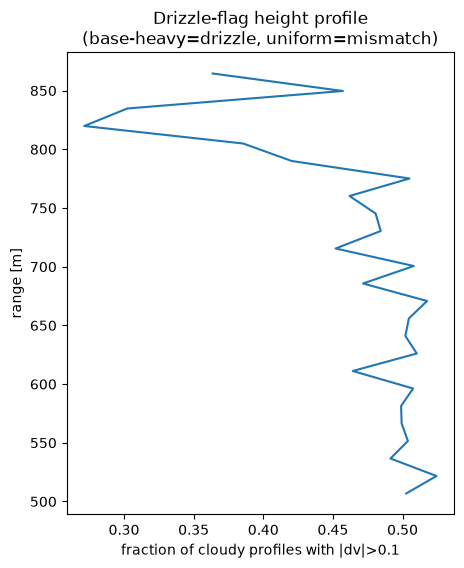

In [76]:
if {"MeanVel_W", "MeanVel_Ka"}.issubset(ds_retrieval.variables):
    dv = (ds_retrieval["MeanVel_W"] - ds_retrieval["MeanVel_Ka"]).where(ds_retrieval["common_mask"])
    dv_vals = dv.values[np.isfinite(dv.values)]
    print(f"velocity-difference stats (in cloud):")
    print(f"  mean   = {dv_vals.mean():+.3f} m/s   (near 0 = well matched)")
    print(f"  median = {np.median(dv_vals):+.3f} m/s")
    print(f"  std    = {dv_vals.std():.3f} m/s     (>0.1 alone explains high kill rate)")
    print(f"  fraction |dv| > 0.1 m/s: {(np.abs(dv_vals) > 0.1).mean():.1%}")

    # Is exceedance near cloud base (real drizzle) or everywhere (mismatch)?
    exceed = (np.abs(dv) > 0.1) & ds_retrieval["common_mask"]
    frac_by_height = exceed.sum("Time") / ds_retrieval["common_mask"].sum("Time")
    fig, ax = plt.subplots(figsize=(5, 6))
    frac_by_height.plot(y="range", ax=ax)
    ax.set_xlabel("fraction of cloudy profiles with |dv|>0.1")
    ax.set_ylabel("range [m]")
    ax.set_title("Drizzle-flag height profile\n(base-heavy=drizzle, uniform=mismatch)")
    plt.show()
else:
    print("MeanVel_W / MeanVel_Ka not in dataset - add them in notebook 02 to run this.")


 ================================================================================================================================================================================================

 INTEGRAL DQ RETRIEVAL - RAW (no time averaging), Tmean kappa

 ================================================================================================================================================================================================

In [77]:
lwc, dq = retrieve_lwc_dq(
    dwr=ds_retrieval["DWR"],
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    common_mask=ds_retrieval["common_mask"],
    min_cloud_gates=6,
    fit_degree=2,
    kappa_mode="tmean",
)


 DQ (cumulative liquid water) - the curve we smooth BEFORE differentiating

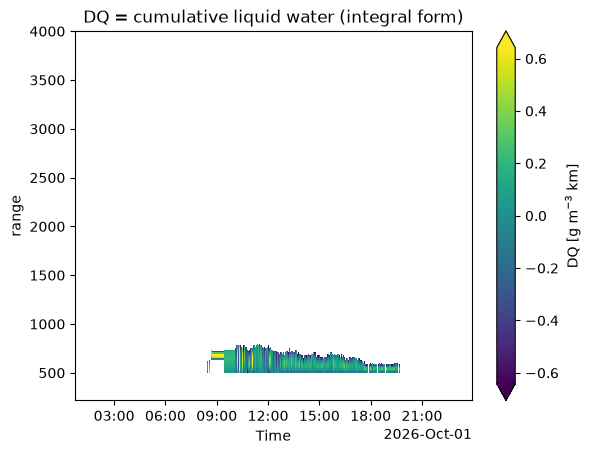

In [78]:
dq.plot(
    x="Time", y="range", cmap="viridis", robust=True,
    cbar_kwargs={"label": "DQ [g m$^{-3}$ km]"},
)
plt.title("DQ = cumulative liquid water (integral form)")
plt.show()


 LWC - Without Averaging

<xarray.DataArray 'LWC' (Time: 29682, range: 229)> Size: 54MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(29682, 229))
Coordinates:
  * Time     (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ... 20...
  * range    (range) float64 2kB 223.6 238.5 253.4 ... 3.952e+03 3.986e+03
Attributes:
    units:      g m-3
    long_name:  Liquid Water Content (integral DQ retrieval)
    method:     DQ polynomial fit deg=2, kappa_mode=tmean


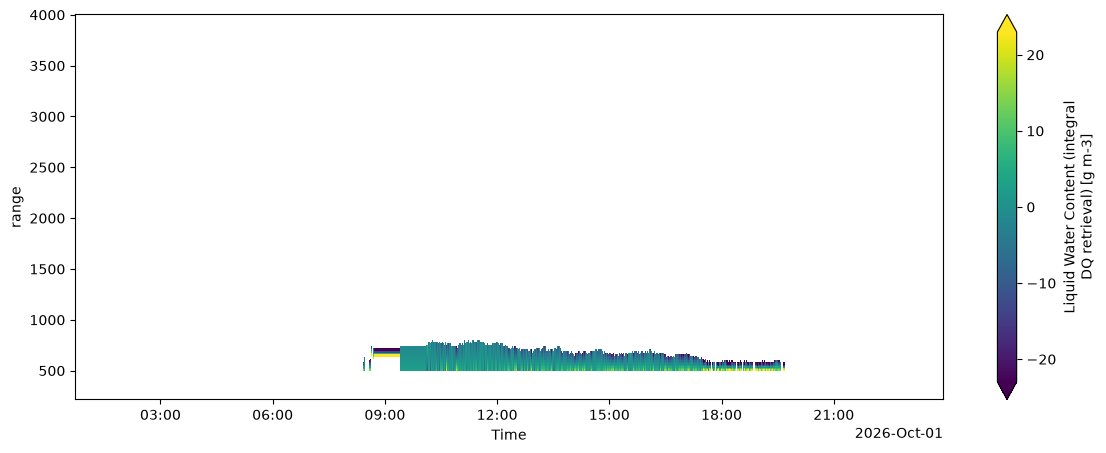

In [79]:
print(lwc)
lwc.plot(x="Time", y="range", figsize=(14, 5), cmap="viridis", robust=True)
plt.show()

In [80]:
print(f"Fraction LWC < 0: "
      f"{float((lwc < 0).sum() / lwc.notnull().sum()):.2%}")
print(f"LWC quantiles: "
      f"p05={float(lwc.quantile(0.05)):.2f}, "
      f"p50={float(lwc.quantile(0.5)):.2f}, "
      f"p95={float(lwc.quantile(0.95)):.2f} g/m³")


Fraction LWC < 0: 53.45%
LWC quantiles: p05=-14.70, p50=-0.32, p95=9.30 g/m³


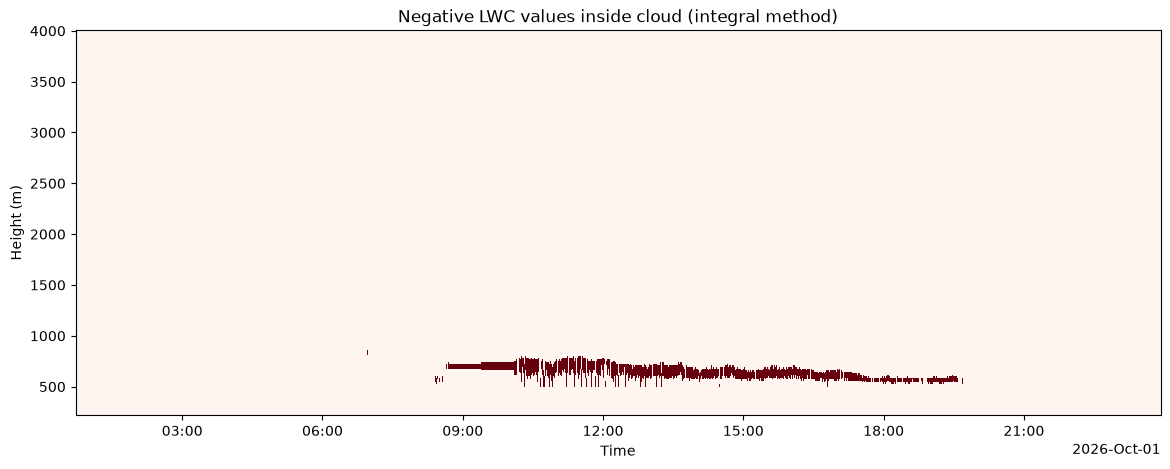

In [81]:
negative_lwc = (lwc < 0) & ds_retrieval["common_mask"]
plt.figure(figsize=(14, 5))
negative_lwc.astype(int).plot(x="Time", y="range", cmap="Reds", add_colorbar=False)
plt.title("Negative LWC values inside cloud (integral method)")
plt.xlabel("Time"); plt.ylabel("Height (m)")
plt.show()


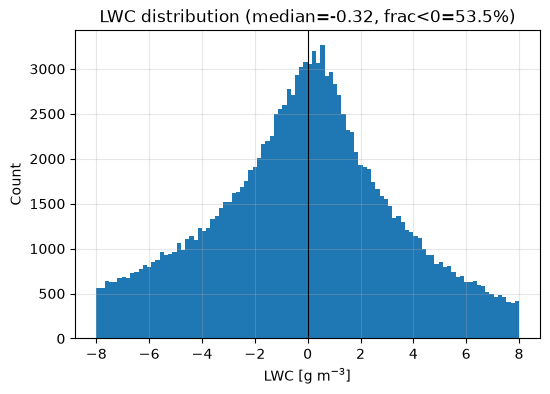

In [82]:
vals = lwc.where(ds_retrieval["common_mask"]).values
vals = vals[np.isfinite(vals)]
plt.figure(figsize=(6, 4))
plt.hist(vals, bins=100, range=(-8, 8))
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("LWC [g m$^{-3}$]"); plt.ylabel("Count")
plt.title(f"LWC distribution (median={np.median(vals):.2f}, "
          f"frac<0={(vals < 0).mean():.1%})")
plt.grid(alpha=0.3)
plt.show()


 ================================================================================================================================================================================================

 TIME-AVERAGED DWR (30 s) THEN DQ RETRIEVAL

 The integral method still benefits from beating down per-gate DWR noise first.

 Average in LINEAR Ze, then form DWR, exactly as in notebook 04.

 ================================================================================================================================================================================================

In [83]:
ze_ka_avg = avg_ze_time(ds_retrieval["Ze_Ka"].sel(range=slice(0, 4000)), window_s=30)
ze_w_avg  = avg_ze_time(ds_retrieval["Ze_W"].sel(range=slice(0, 4000)),  window_s=30)

dwr_2km_smoothed = ze_ka_avg - ze_w_avg
dwr_2km_smoothed.name = "DWR"


In [84]:
# %%

In [85]:
gate_threshold = 1.0  # dB

def despike_1d(dwr_1d, threshold=1.0):
    out = dwr_1d.copy()
    n = len(dwr_1d)
    for i in range(1, n - 1):
        left = dwr_1d[i] - dwr_1d[i - 1]
        right = dwr_1d[i] - dwr_1d[i + 1]
        is_spike = (
            np.abs(left) > threshold
            and np.abs(right) > threshold
            and np.sign(left) == np.sign(right)
        )
        if is_spike and not (np.isnan(dwr_1d[i - 1]) or np.isnan(dwr_1d[i + 1]) or np.isnan(dwr_1d[i])):
            out[i] = dwr_1d[i - 1] + (dwr_1d[i + 1] - dwr_1d[i - 1]) * 0.5
    return out

dwr_2km_filt = xr.apply_ufunc(
    despike_1d, dwr_2km_smoothed,
    input_core_dims=[["range"]], output_core_dims=[["range"]],
    kwargs={"threshold": gate_threshold}, vectorize=True,
)
dwr_2km_filt.name = "DWR"
dwr_2km_filt.attrs = dwr_2km_smoothed.attrs

n_replaced = int((np.abs(dwr_2km_filt - dwr_2km_smoothed) > 1e-9).sum())
print(f"Gates replaced by interpolation: {n_replaced} "
      f"({n_replaced / dwr_2km_smoothed.size:.2%} of all gates)")


Gates replaced by interpolation: 7210 (0.11% of all gates)


In [86]:
lwc_2, dq_2 = retrieve_lwc_dq(
    dwr=dwr_2km_filt,                       # despiked, 30 s averaged DWR
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    common_mask=ds_retrieval["common_mask"],
    min_cloud_gates=6,
    fit_degree=2,
    kappa_mode="tmean",
)


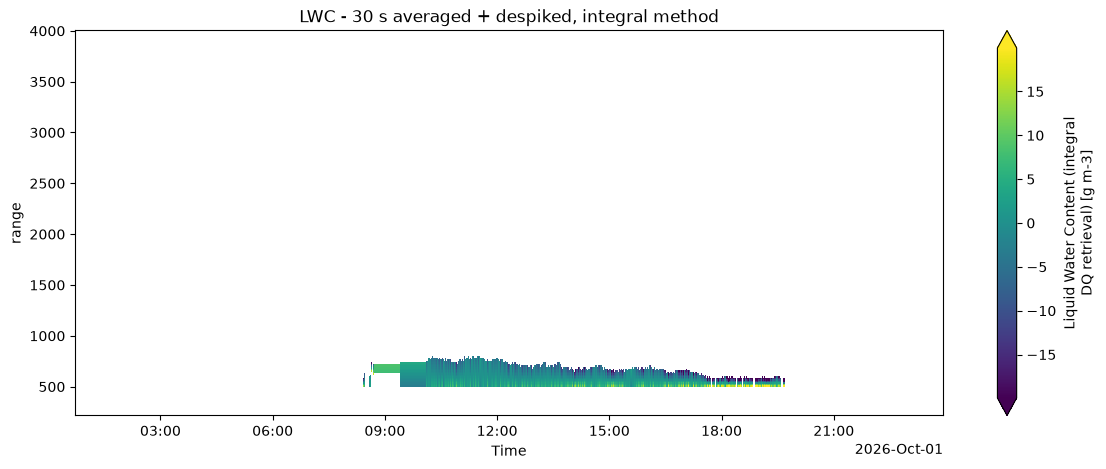

In [87]:
lwc_2.plot(x="Time", y="range", figsize=(14, 5), cmap="viridis", robust=True)
plt.title("LWC - 30 s averaged + despiked, integral method")
plt.show()


In [88]:
print(f"Fraction LWC < 0: "
      f"{float((lwc_2 < 0).sum() / lwc_2.notnull().sum()):.2%}")
print(f"LWC quantiles: "
      f"p05={float(lwc_2.quantile(0.05)):.2f}, "
      f"p50={float(lwc_2.quantile(0.5)):.2f}, "
      f"p95={float(lwc_2.quantile(0.95)):.2f} g/m³")


Fraction LWC < 0: 51.58%
LWC quantiles: p05=-12.37, p50=-0.12, p95=7.75 g/m³


 ================================================================================================================================================================================================

 KAPPA-RESOLVED VARIANT (answers Q1: keep kappa inside the integral)

 For thin, narrow-temperature clouds this should be ~identical to Tmean.

 ================================================================================================================================================================================================

In [89]:
lwc_res, dq_res = retrieve_lwc_dq(
    dwr=dwr_2km_filt,
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    common_mask=ds_retrieval["common_mask"],
    min_cloud_gates=6,
    fit_degree=2,
    kappa_mode="resolved",
)

diff = (lwc_res - lwc_2).where(ds_retrieval["common_mask"])
print(f"Tmean vs resolved: mean |diff| = {float(np.abs(diff).mean()):.4f} g/m³ "
      f"(expected tiny for ~1 K clouds)")


Tmean vs resolved: mean |diff| = 0.0144 g/m³ (expected tiny for ~1 K clouds)


 ================================================================================================================================================================================================

 LWP CLOSURE: DQ-derived radar LWP  vs  MWR LWP

 ================================================================================================================================================================================================

 LWP_radar = DQ(cloud top) * 1000  [g m-2]. Take the top valid DQ per profile.

In [90]:
def dq_to_lwp(dq_da, mask):
    """LWP [g/m2] from DQ endpoints, per profile, lowest contiguous segment."""
    dqm = dq_da.where(mask)
    top  = dqm.ffill("range").isel(range=-1)     ##ffill : Forward fill means: replace NaNs with the previous valid value.
    base = dqm.bfill("range").isel(range=0)     # Taking Top Minus Bottom removes calibration errors between the two radars which are integrated in DQ Retrieval and automatically removed by Zhus derivative ( Bias is constant)
    lwp = (top - base) * 1000.0
    lwp.attrs["units"] = "g m-2"
    return lwp.where(mask.any("range"))

lwp_radar = dq_to_lwp(dq_2, ds_retrieval["common_mask"])

# Optional: time-average LWP over 5 min to beat down residual noise
lwp_radar_5min = lwp_radar.rolling(Time=int(5 * 60 / 30), center=True, min_periods=1).mean()


-Correlation = 0.9, slope = 0.5, bias ≈ 0 → the radar follows the temporal variability very well but consistently retrieves only about half of the true LWP.

-Correlation = 0.1, slope = 1.0 → the average scaling looks right, but the retrieval hardly tracks the actual changes from profile to profile.

-Correlation = 0.8, slope = 1.0, bias = -30 g/m² → the retrieval follows the variability and has the correct scaling, but there is a nearly constant negative offset that shifts all values downward.

In [91]:
   time_step_s = float(np.median(np.diff(lwp_radar.Time.values)) / np.timedelta64(1, "s"))
   lwp_radar_5min = lwp_radar.rolling(Time=max(1, round(300 / time_step_s)), center=True, min_periods=1).mean()

In [92]:
from scipy.ndimage import label

def dq_to_lwp_layers(dq_da, mask):
    """Per profile: LWP summed over every cloud layer, number of layers, total cloud thickness,
    lowest cloud base and highest cloud top.
    A layer = a contiguous run of gates where the DQ retrieval produced a value (same idea as
    retrieve_lwc_dq, which labels contiguous segments with scipy.ndimage.label)."""
    dq = dq_da.where(mask).transpose("Time", "range")
    dq_values = dq.values                                      # (time, range), NaN outside retrieved layers
    gate_height = dq["range"].values.astype(float)             # [m]
    gate_width = np.gradient(gate_height)                      # depth each gate stands for [m] (works on non-uniform grids)

    n_profiles = dq_values.shape[0]
    lwp_g_m2        = np.full(n_profiles, np.nan)
    n_layers        = np.zeros(n_profiles, dtype=int)
    thickness_m     = np.full(n_profiles, np.nan)
    cloud_base_m    = np.full(n_profiles, np.nan)
    cloud_top_m     = np.full(n_profiles, np.nan)

    for t in range(n_profiles):
        layer_id, n_found = label(np.isfinite(dq_values[t]))  # 1, 2, ... for each contiguous layer, 0 = no value
        if n_found == 0:
            continue                                           # no retrieved cloud in this profile -> stays NaN / 0
        lwp_sum, depth_sum = 0.0, 0.0
        for layer in range(1, n_found + 1):
            gates = np.flatnonzero(layer_id == layer)          # gate indices of this layer, bottom to top
            # DQ restarts at ~0 at every layer base, so each layer contributes (DQ at its top - DQ at its base).
            # Top minus base cancels a constant Ka/W calibration offset within each layer.
            lwp_sum   += dq_values[t, gates[-1]] - dq_values[t, gates[0]]
            depth_sum += gate_width[gates].sum()
        lwp_g_m2[t]     = lwp_sum * 1000.0                     # DQ is g m-3 km -> x1000 = g m-2
        n_layers[t]     = n_found
        thickness_m[t]  = depth_sum                            # total cloud depth, all layers together
        retrieved = np.flatnonzero(np.isfinite(dq_values[t]))
        cloud_base_m[t] = gate_height[retrieved[0]]            # lowest retrieved gate
        cloud_top_m[t]  = gate_height[retrieved[-1]]           # highest retrieved gate

    time = dq["Time"].values
    return xr.Dataset({
        "lwp":             ("Time", lwp_g_m2,     {"units": "g m-2", "long_name": "radar LWP, sum over all layers"}),
        "n_layers":        ("Time", n_layers,     {"long_name": "number of retrieved cloud layers"}),
        "cloud_thickness": ("Time", thickness_m,  {"units": "m", "long_name": "total depth of all retrieved layers"}),
        "cloud_base":      ("Time", cloud_base_m, {"units": "m", "long_name": "lowest retrieved gate (above radar)"}),
        "cloud_top":       ("Time", cloud_top_m,  {"units": "m", "long_name": "highest retrieved gate (above radar)"}),
    }, coords={"Time": time})


radar_cloud = dq_to_lwp_layers(dq_2, ds_retrieval["common_mask"])
lwp_radar = radar_cloud["lwp"]                       # same name as before, so your later cells keep working

# 5-min running mean, window computed from the real time step (not the Cabauw 30 s)
time_step_s = float(np.median(np.diff(lwp_radar.Time.values)) / np.timedelta64(1, "s"))
window = max(1, round(300 / time_step_s))
lwp_radar_5min = lwp_radar.rolling(Time=window, center=True, min_periods=1).mean()
cloud_thickness_5min = radar_cloud["cloud_thickness"].rolling(Time=window, center=True, min_periods=1).mean()

print(f"profiles with cloud: {int((radar_cloud.n_layers > 0).sum())} | with 2+ layers: {int((radar_cloud.n_layers > 1).sum())}")
print(f"cloud thickness: median {float(radar_cloud.cloud_thickness.median()):.0f} m")

profiles with cloud: 14269 | with 2+ layers: 0
cloud thickness: median 179 m


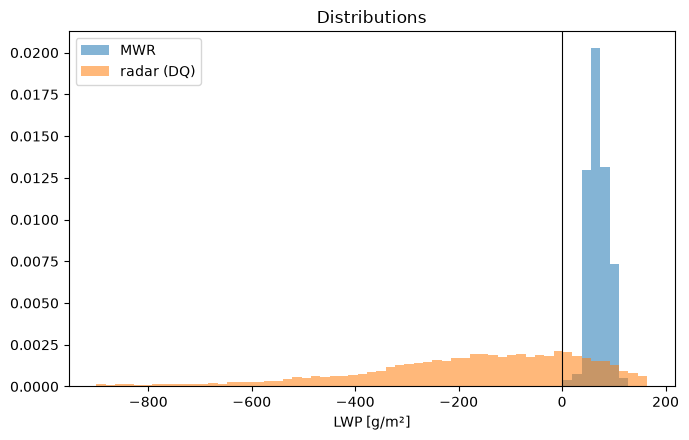

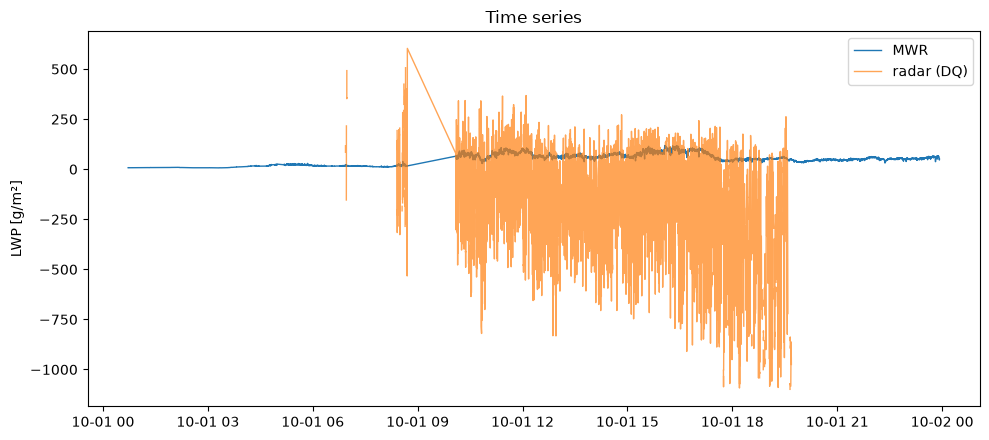

MWR   : mean   +69.5 std   18.4 p05   +43.5 p50   +66.9 p95  +100.3
radar : mean  -174.3 std  235.4 p05  -629.5 p50  -140.6 p95  +132.3


In [93]:
# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_radar.values
good = np.isfinite(x) & np.isfinite(y)

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar (DQ)", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title("Distributions")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe
plt.figure(figsize=(10, 4.5))
plt.plot(ds_retrieval["Time"], x, label="MWR", lw=1)
plt.plot(ds_retrieval["Time"], y, label="radar (DQ)", lw=1, alpha=0.7)
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

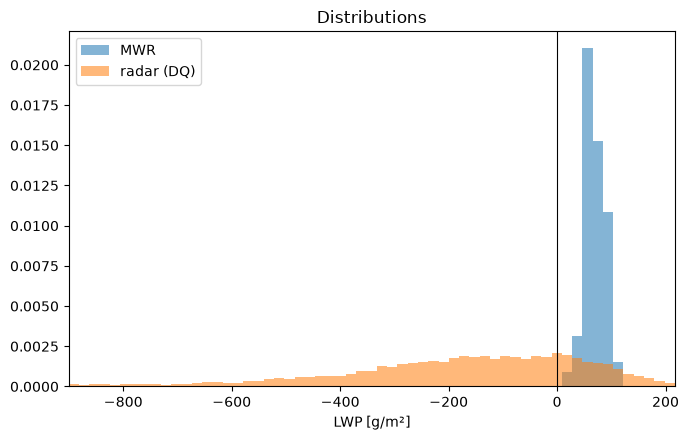

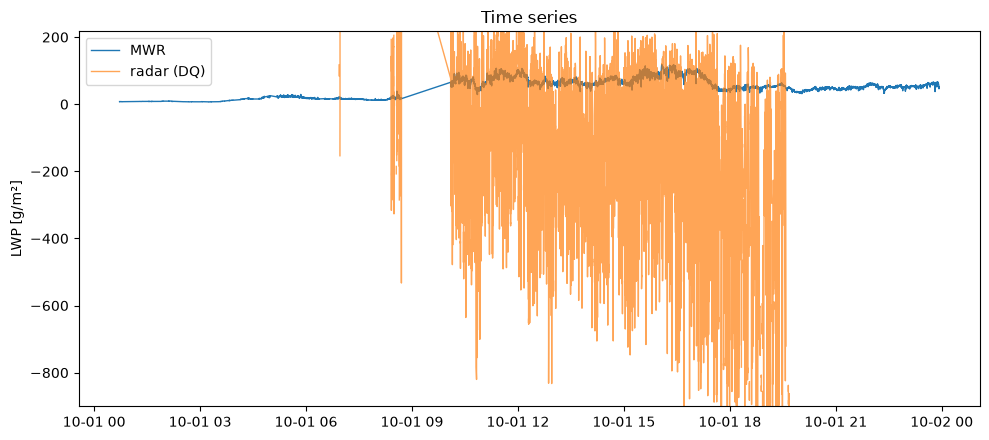

MWR   : mean   +69.5 std   18.4 p05   +43.5 p50   +66.9 p95  +100.3
radar : mean  -174.3 std  235.4 p05  -629.5 p50  -140.6 p95  +132.3


In [94]:
# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_radar.values
good = np.isfinite(x) & np.isfinite(y)

# Zoom range for both plots — based on percentiles so outliers don't blow up the axes.
# Adjust these two numbers directly if you want to zoom in/out further.
LWP_MIN = min(np.nanpercentile(y[good], 1), np.nanpercentile(x[good], 1), 0)
LWP_MAX = max(np.nanpercentile(y[good], 99), np.nanpercentile(x[good], 99))

bins = np.linspace(LWP_MIN, LWP_MAX, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar (DQ)", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title("Distributions")
plt.xlim(LWP_MIN, LWP_MAX)
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe
plt.figure(figsize=(10, 4.5))
plt.plot(ds_retrieval["Time"], x, label="MWR", lw=1)
plt.plot(ds_retrieval["Time"], y, label="radar (DQ)", lw=1, alpha=0.7)
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.ylim(LWP_MIN, LWP_MAX)
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

Per-profile closure:


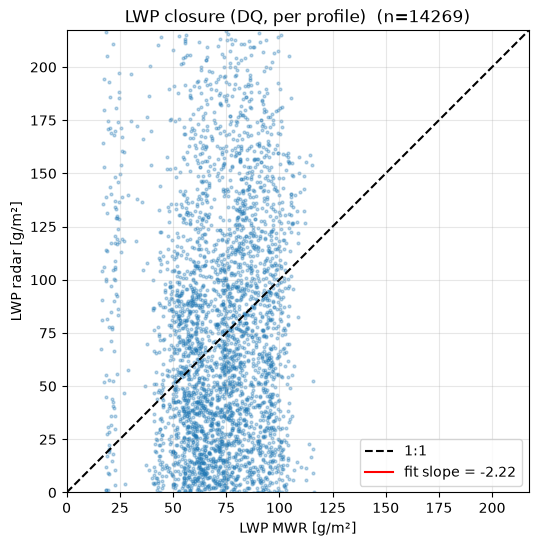

  slope through origin: -2.22   (want ~1.0)
  correlation:          0.15   (want > 0.7)
  bias radar - MWR:     -243.7 g/m²

5-min averaged closure (noise averages down here):


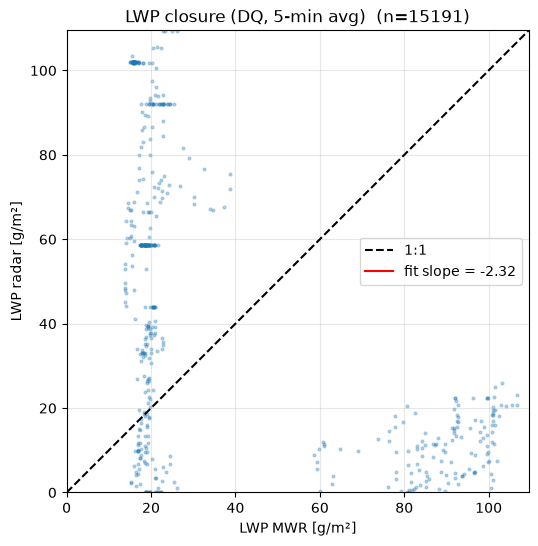

  slope through origin: -2.32   (want ~1.0)
  correlation:          0.22   (want > 0.7)
  bias radar - MWR:     -246.8 g/m²


In [95]:
def closure_plot(x, y, title):
    good = np.isfinite(x) & np.isfinite(y) & (x > 5)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(x[good], y[good], s=4, alpha=0.3)
    lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
    ax.plot([0, lim], [0, lim], "k--", label="1:1")
    slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)      # Least squares solution of y = a*x . It minimizes Sum((yi​−axi​)^2). Analytical Solution of that is a = equation in Code
    ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
    ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
    ax.set_title(f"{title}  (n={good.sum()})")
    plt.show()
    corr = np.corrcoef(x[good], y[good])[0, 1]
    print(f"  slope through origin: {slope:.2f}   (want ~1.0)")                     # I everything is perfect all dots on line. --> All MWR LWP equals Radar LWP. So Slope answers: How much liquid water do I retrieve compared with the MWR
    print(f"  correlation:          {corr:.2f}   (want > 0.7)")                     #Correlation : If LWP Radar goes up and MWR LWP goes down for a certain measurement the correlation is negative and vice versa.
    print(f"  bias radar - MWR:     {np.nanmean(y[good] - x[good]):+.1f} g/m²")     # Bias is the average difference. Should be close to zero

print("Per-profile closure:")
closure_plot(ds_retrieval["LWP"].values, lwp_radar.values, "LWP closure (DQ, per profile)")

print("\n5-min averaged closure (noise averages down here):")
closure_plot(ds_retrieval["LWP"].values, lwp_radar_5min.values, "LWP closure (DQ, 5-min avg)")


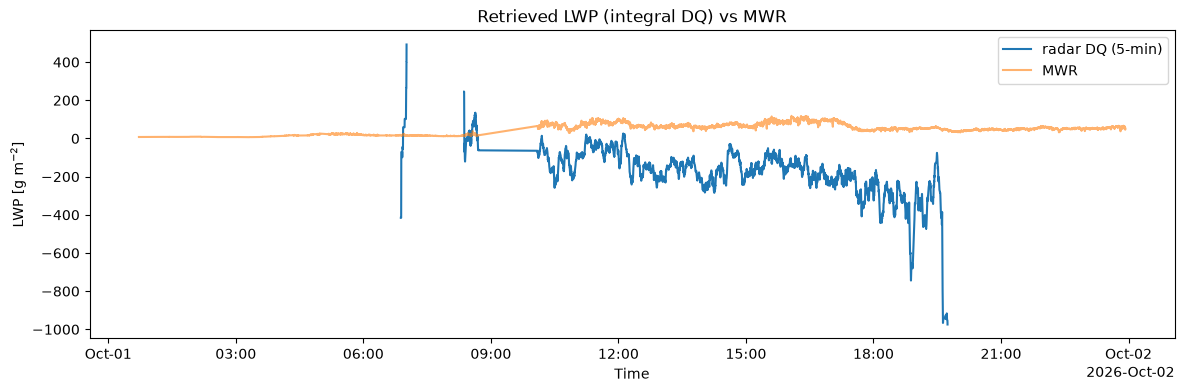

In [96]:
fig, ax = plt.subplots(figsize=(14, 4))
lwp_radar_5min.plot(ax=ax, label="radar DQ (5-min)")
ds_retrieval["LWP"].plot(ax=ax, label="MWR", alpha=0.6)
ax.set_title("Retrieved LWP (integral DQ) vs MWR")
ax.set_ylabel("LWP [g m$^{-2}$]"); ax.set_xlabel("Time"); ax.legend()
plt.show()


 ================================================================================================================================================================================================

 SIDE-BY-SIDE: integral DQ  vs  Zhu local-derivative (same input DWR)

 ================================================================================================================================================================================================

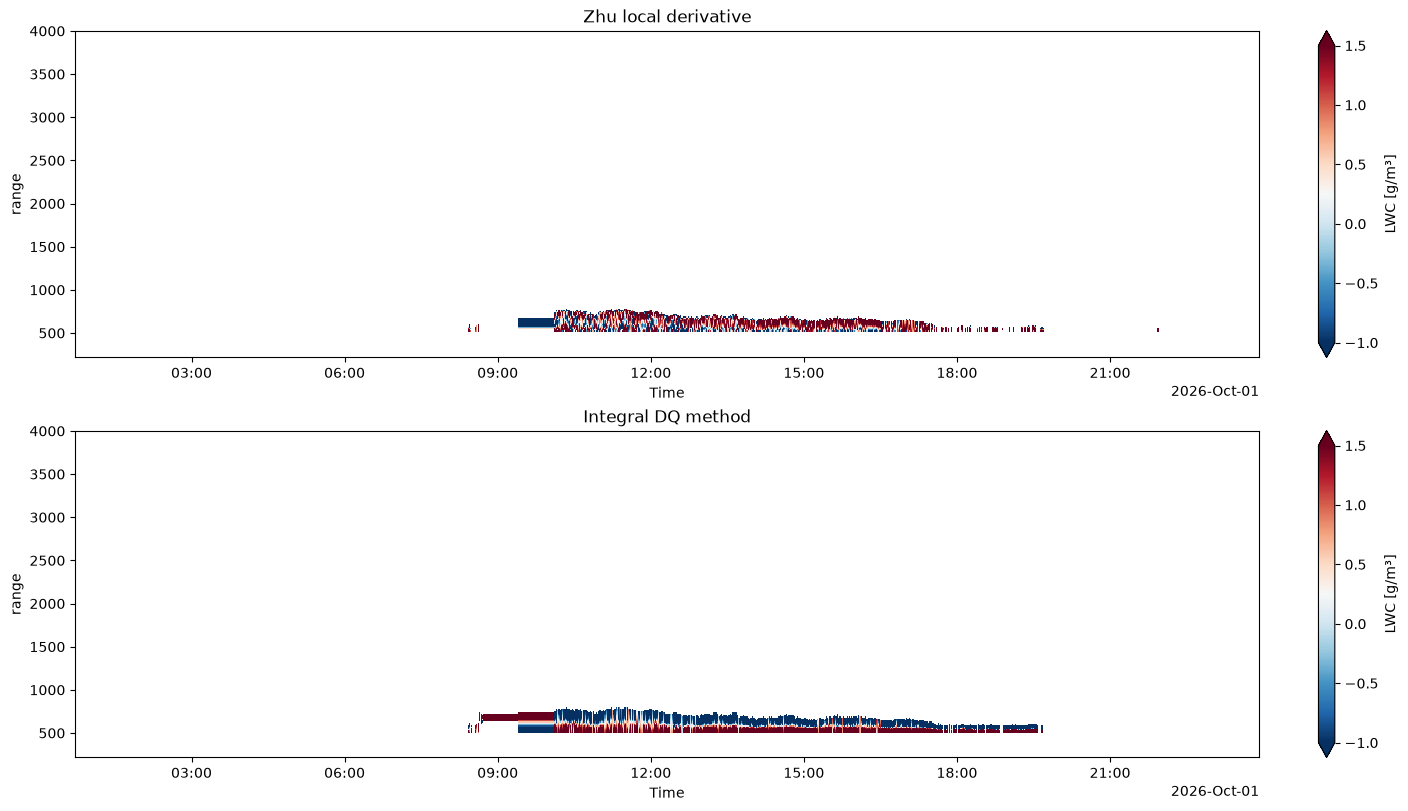

Zhu   fraction LWC<0: 24.4%
DQ    fraction LWC<0: 51.6%


In [97]:
lwc_zhu, deriv_zhu, m_eff_zhu, n_windows_zhu, n_used_zhu = retrieve_lwc_zhu(
    dwr=dwr_2km_filt,
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    cloud_mask=ds_retrieval["common_mask"],
    N_default=9,
    min_cloud_gates=3,
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
lwc_zhu.where(ds_retrieval["common_mask"]).plot(
    x="Time", y="range", ax=axes[0], vmin=-1, vmax=1.5, cmap="RdBu_r",
    cbar_kwargs={"label": "LWC [g/m³]"})
axes[0].set_title("Zhu local derivative")
lwc_2.where(ds_retrieval["common_mask"]).plot(
    x="Time", y="range", ax=axes[1], vmin=-1, vmax=1.5, cmap="RdBu_r",
    cbar_kwargs={"label": "LWC [g/m³]"})
axes[1].set_title("Integral DQ method")
plt.show()

print(f"Zhu   fraction LWC<0: {float((lwc_zhu < 0).sum()/lwc_zhu.notnull().sum()):.1%}")
print(f"DQ    fraction LWC<0: {float((lwc_2   < 0).sum()/lwc_2.notnull().sum()):.1%}")


Mean DQ at cloud base:   -0.096 g m^-3 km
Median DQ at cloud base: -0.091 g m^-3 km
Std DQ at cloud base:    0.060 g m^-3 km


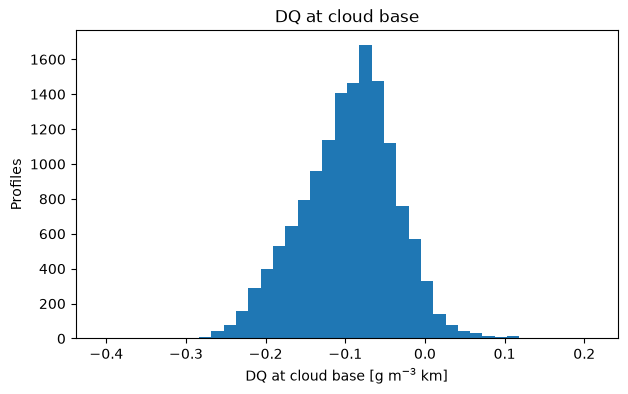

In [98]:
dq_base = []

mask = ds_retrieval["common_mask"].values

for t in range(mask.shape[0]):
    idx = np.flatnonzero(mask[t])
    if idx.size == 0:
        continue

    i_base = idx.min()
    dq_base.append(float(dq_2.isel(Time=t, range=i_base)))

dq_base = np.array(dq_base)

print(f"Mean DQ at cloud base:   {np.nanmean(dq_base):.3f} g m^-3 km")
print(f"Median DQ at cloud base: {np.nanmedian(dq_base):.3f} g m^-3 km")
print(f"Std DQ at cloud base:    {np.nanstd(dq_base):.3f} g m^-3 km")

plt.figure(figsize=(7,4))
plt.hist(dq_base[np.isfinite(dq_base)], bins=40)
plt.xlabel("DQ at cloud base [g m$^{-3}$ km]")
plt.ylabel("Profiles")
plt.title("DQ at cloud base")
plt.show()

# Cloudbase has fine Values for DWR. (Close to 0)  --> Problem is not Bias or big DWR at Cloud Base already

In [99]:
# 1. per-gate DWR noise (your existing diagnostic, on dwr_2km_filt + common_mask)
D = dwr_2km_filt.where(ds_retrieval["common_mask"]).values
diffs = D[:, 1:] - D[:, :-1]
sigma = np.nanstd(diffs[np.isfinite(diffs)]) / np.sqrt(2)             #Var(n2​−n1​)=Var(n2​)+Var(n1​)=2σ^2   --> Std(diff)=sqrt(2)*σ
print(f"sigma_DWR = {sigma:.2f} dB  ->  implied LWP noise = {sigma*np.sqrt(2)/(2*3.4)*1000:.0f} g/m2")     # We look at the Variance of LWP=(DWRtop​−DWRbase)/(2Δκ)*​​1000.    For each MEasurement of DWR they each have Variance σ^2. Subtracting them gives Var(DWRtop​−DWRbase​)=2* σ^2  ==> σ_std= sqrt(2) * σ. Thats why np.sqrt(2)
# We estimate the LWP uncertainty from
#
#     LWP = (DWR_top - DWR_base) / (2Δκ) * 1000
#
# Assume the DWR measurements at cloud top and cloud base each have
# independent random noise with standard deviation σ_DWR.
#
# Then
#     Var(DWR_top - DWR_base)
#         = Var(DWR_top) + Var(DWR_base)
#         = 2σ_DWR²
#
# so the standard deviation of the DWR difference is
#
#     σ_ΔDWR = √2 · σ_DWR.
#
# Propagating this through the LWP equation gives
#
#     σ_LWP = (√2 · σ_DWR) / (2Δκ) * 1000.


# 2. how much does MWR LWP actually vary on this day?
print(f"MWR LWP: std={float(ds_retrieval['LWP'].std()):.0f}, "
      f"p05={float(ds_retrieval['LWP'].quantile(0.05)):.0f}, "
      f"p95={float(ds_retrieval['LWP'].quantile(0.95)):.0f} g/m2")

sigma_DWR = 1.29 dB  ->  implied LWP noise = 269 g/m2
MWR LWP: std=27, p05=8, p95=95 g/m2


Noise propagation, with Δκ ≈ 3.4:\\

sigma_DWR=0.2 dB  ->  LWP noise ~  42 g/m2\\

sigma_DWR=0.3 dB  ->  LWP noise ~  62 g/m2\\

sigma_DWR=0.5 dB  ->  LWP noise ~ 104 g/m2\\

sigma_DWR=1.0 dB  ->  LWP noise ~ 208 g/m2\\

And the correlation you can possibly achieve, given MWR LWP variability S and radar noise N (corr = S/√(S²+N²)):\\

MWR LWP std= 50 g/m2 -> N=60: 0.64  ; N=100: 0.45  ; N=150: 0.32\\

MWR LWP std=120 g/m2 -> N=60: 0.89  ; N=100: 0.77  ; N=150: 0.62

## LWP Noise is way bigger than MWR LWP Uncertainty!!!

--> poor radar–MWR correlation is largely explained by the measurement noise itself. In that case, changing the fitting method or smoothing strategy alone is unlikely to produce a dramatic improvement in LWP agreement.

In [100]:
n_gates   = ds_retrieval["common_mask"].sum("range")
top_gate  = ds_retrieval["common_mask"] * ds_retrieval["range"]
cloud_top = top_gate.where(ds_retrieval["common_mask"]).max("range")     #Every cloud gets number. Mask True is 1 and this is then multiplied by the range. Highest number of each profile is taken
x = ds_retrieval["LWP"].values
for name, v in [("n_gates", n_gates.values), ("cloud_top", cloud_top.values)]:
    g = np.isfinite(x) & np.isfinite(v) & (x > 5)               # I look at all Values of MWR LWP above 5 and not NaN
    print(f"corr(MWR LWP, {name}) = {np.corrcoef(x[g], v[g])[0,1]:+.2f}")     # computes r= Cov(x,y) /(σ_x*σ_y)  --> If high MWR LWP and small clou_top then Cov(x,y)<0
    # The corrcoef looks at the mean of MWR LWP and the height and comapares the Values at a certain time with it. (x_i​−xˉ)(v_i​−vˉ)  If x_i is higher than the mean and v_i lower the result will be negative and it shows negative correlation.
    #Looks at the Correlation of both the Gates and the Cloud top "Range" with the MWR LWP

corr(MWR LWP, n_gates) = +0.81
corr(MWR LWP, cloud_top) = +0.59


In [101]:
print(f"Mean MWR LWP = {float(ds_retrieval['LWP'].mean(skipna=True)):.2f} g/m²")

Mean MWR LWP = 48.67 g/m²


In [102]:
# %% Export DQ retrieval outputs for notebook 06
from pathlib import Path
import xarray as xr

ds_output_dq = xr.Dataset(
    {
        "lwc_dq": lwc_2.rename("lwc_dq"),
        "dq":     dq_2.rename("dq"),
    },
    attrs={
        "description": "Integral (DQ) retrieval output",
        "fit_degree": 2,
        "kappa_mode": "tmean",
        "min_cloud_gates": 6,
        "created_by": "05_dq_retrieval.ipynb",
    },
)

out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_dq.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_output_dq.to_netcdf(out_path)
print(f"Saved → {out_path}")

Saved → ..\data\processed\20261001_pallas_interpolation\retrieval_output_dq.nc
